# Feature reduction

### <i> Using KPCA 

<br>
<br>

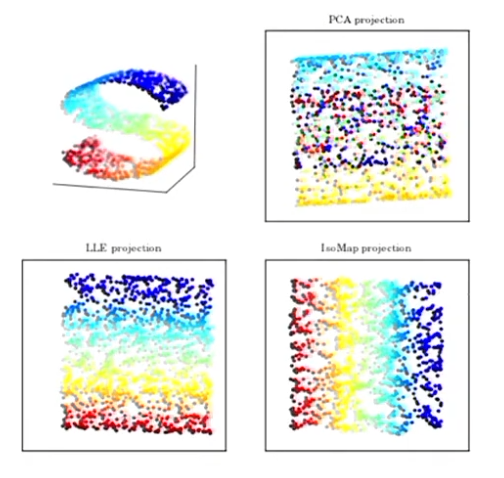


[18 minute video explaining KPCA and linear subspaces](https://www.youtube.com/watch?v=HbDHohXPLnU)

<br>
<br>

`KPCA` (Kernel `PCA`) is a variant of `PCA` which uses a kernel function (such as `RBF` or `Polynomial`) to untangle deeply non-linear and nested data in linear subspace. 

There's a lot of complex math involved behind this trick, so to save us the time and effort, let me just show you the use-case.

### Use case

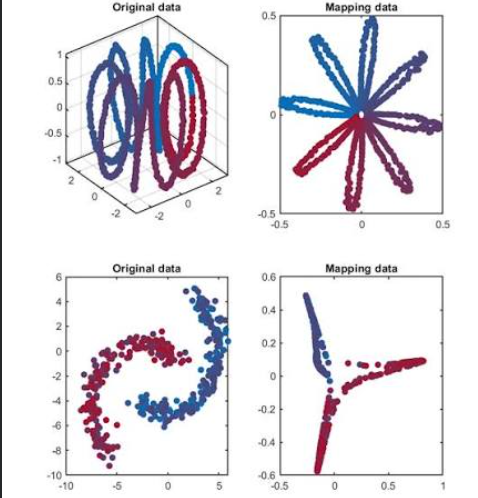

`PCA` has a fundamental flaw -- Non-linearity. And I don't mean that PCA can't handle some stuttering and seasonality...

I mean nested, concentric shapes and DEEPLY non-linear data like what is seen above. `KPCA` was created for that reason. To handle

relationships between features which cannot be interpreted by lines (DNA, hyperspatial imaging, etc). 

<br>


`KPCA` also works best when using `Linear` machine learning models ( such as`RidgeClassifier`, `LinearRegressor`)

### Code

In [1]:
from sklearn.datasets import fetch_california_housing

import numpy as np
import pandas as pd
import seaborn as sns

# Grabbing housing dataset from sklearn. 
housing = fetch_california_housing()

# Loading dataframe
df = pd.DataFrame(housing.data,columns=housing.feature_names)

# Target housing. For some reason it's separate from the dataset.
df["MedHouseVal"] = housing.target

df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


### Problem:

<i> Say we want to use feature reduction and get 5 features instead of 8? Well, that might be a problem because `PCA` will not be able to easily handle this data, since the data stutters, varies a lot, and their relationships are complex. 

<Axes: xlabel='Population', ylabel='MedHouseVal'>

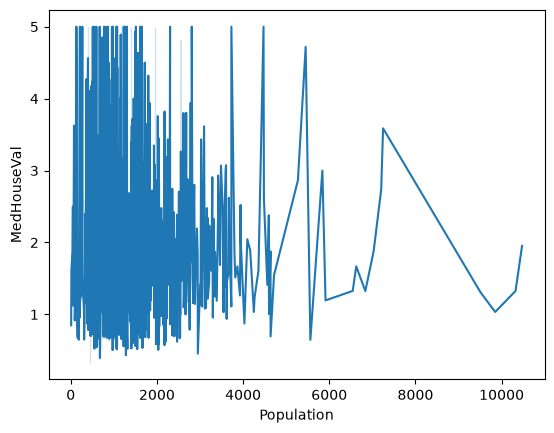

In [2]:
# Look at the amount of noise and non-linearity in the data.
sns.lineplot(df.sample(1000), x="Population", y="MedHouseVal")

# Seeing relationships like this means KPCA might be worth a shot. 

---

### Using KPCA -- Experiment 1:

<i> Now, it's time to use `KPCA` and see how it fares with this dataset. Let's start with `n_components = 2` since that is the easiest to visualize.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import KernelPCA
from sklearn.metrics.pairwise import rbf_kernel

# Separate features and target
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize KPCA
kpca = KernelPCA(
    n_components=2,
    kernel="rbf",
    gamma=0.1
)

# Transform the data
X_kpca = kpca.fit_transform(X_scaled)

# Estimate kernel variance retained
kernel_matrix = rbf_kernel(X_scaled, gamma=0.1)

total_kernel_variance = np.trace(
    kernel_matrix - np.outer(
        kernel_matrix.mean(axis=1),
        np.ones(kernel_matrix.shape[0])
    )
)

# Metrics 
variance_retained = (kpca.eigenvalues_.sum() / total_kernel_variance)

print(f"Kernel variance retained: {variance_retained:.2%}")

# Convert to dataframe
kpca_df = pd.DataFrame(
    X_kpca,
    columns=["KPCA1", "KPCA2"]
)

# Add target for visualization
kpca_df["MedHouseVal"] = y.values

# The closer to 100% the better!

Kernel variance retained: 41.66%


### Visualizing `KPCA`

<i>

<strong style='color:red'> WARNING: </strong> 

Most `KPCA` visualizations are incredibly abstract and difficult to read. But you can still get something out of it, namely:

<br>
<br>

However, no matter how strange it looks, simply:

* Check for overlap.

* Check for clustering.

<br>
<br>

<strong style='color:teal'> NOTE: </strong>

A simpler source of truth trying your model out with these approaches and seeing if it improves the metrics (I made benchmarks in `featreduction_benchmark_PCA_KPCA.ipynb`, worth checking out!)

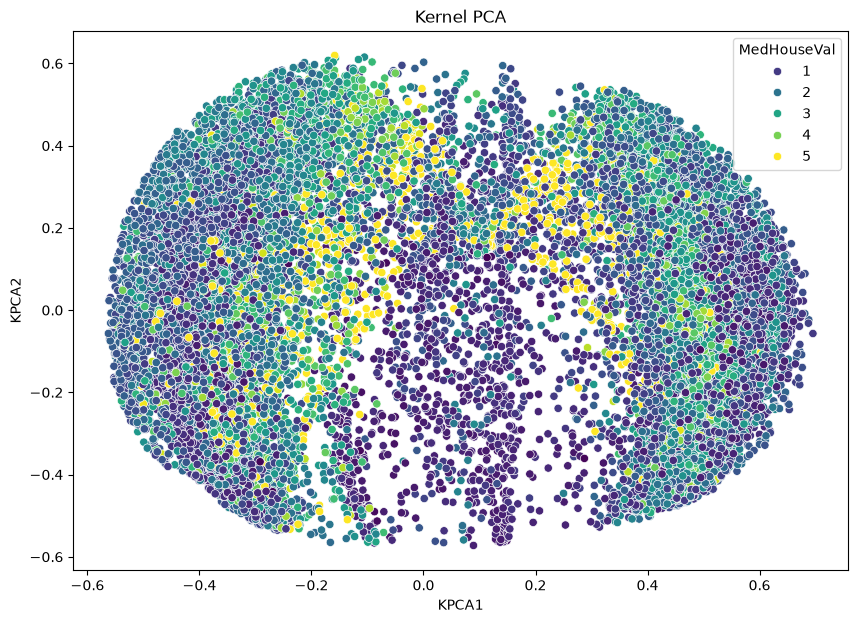

In [4]:
import matplotlib.pyplot as plt


# A scatterplot of the 
plt.figure(figsize=(10, 7))
sns.scatterplot(data=kpca_df,x="KPCA1",y="KPCA2",hue="MedHouseVal",palette="viridis",)

plt.title("Kernel PCA")
plt.show()

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3> Observations: </h3>


We do see some clusters but we can still see a HUGE amount of overlap, this tells us to add more `n_components`.

</div>



---

### Using KPCA -- Experiment 2, with `n_components = 6`

<i> For experiment 2, let's add more components

In [5]:
# Using KPCA -- Experiment 2, with `n_components = 6`

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import KernelPCA
from sklearn.metrics.pairwise import rbf_kernel

# Separate features and target
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize KPCA
kpca = KernelPCA(
    n_components=6,
    kernel="rbf",
    gamma=0.1
)

# Transform the data
X_kpca = kpca.fit_transform(X_scaled)

# Estimate kernel variance retained
kernel_matrix = rbf_kernel(X_scaled, gamma=0.1)

total_kernel_variance = np.trace(
    kernel_matrix - np.outer(
        kernel_matrix.mean(axis=1),
        np.ones(kernel_matrix.shape[0])
    )
)

# Metrics 
variance_retained = (kpca.eigenvalues_.sum() / total_kernel_variance)

print(f"Kernel variance retained: {variance_retained:.2%}")

# Convert to dataframe
kpca_df = pd.DataFrame(
    X_kpca,
    columns=["KPCA1", "KPCA2", "KPCA3", "KPCA4", "KPCA5", "KPCA6"]
)

# Add target for visualization
kpca_df["MedHouseVal"] = y.values

# The closer to 100% the better!

Kernel variance retained: 69.42%


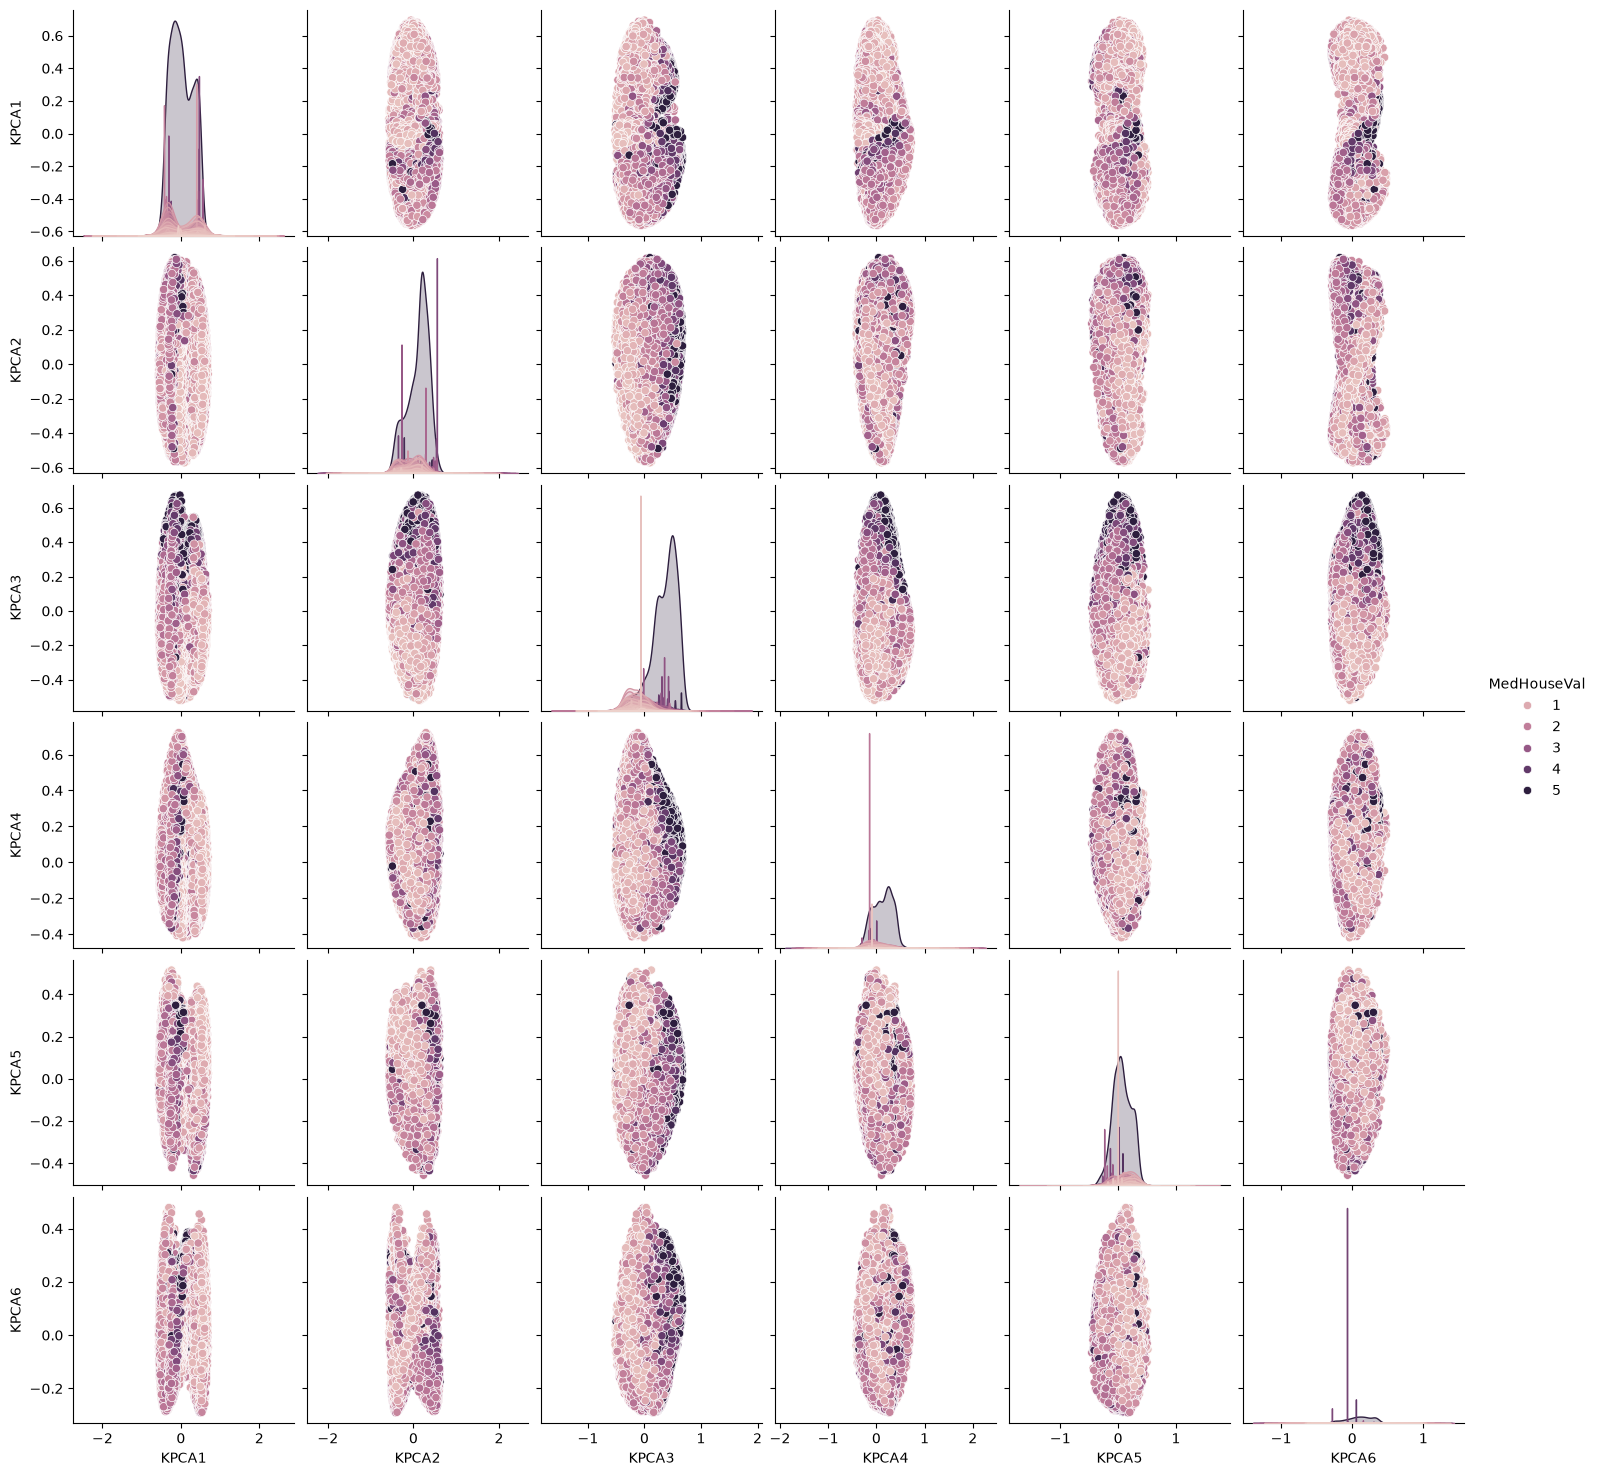

In [6]:
# Now, let's use a pairplot to visualize the results. 
# Again, this is going to be an explosion of data. 
# Just worry about the overlapping and distinct clustering.

# LOWER THE SAMPLE SIZE if this takes too long.
kpca_df_sample = kpca_df.sample(700)

sns.pairplot(kpca_df, hue="MedHouseVal")

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3> Observations: </h3>


Now the clusters seem to be much more clearly dividing the classes, though it's still difficult to read!

The reason it looks strange. That comes with the nature of the Kernel Trick with KPCA, as it performs complex steps to try to flatten the data in sublinear space. 

</div>


---
<i>

### Reconstruction

Just like normal `PCA` we can reconstruct the data, but this comes with a RECONSTRUCTION COST, where some inaccuracy will exist when recreating the dataframe again.

In [7]:
from sklearn.decomposition import KernelPCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Let's add the original df here to make some metrics
original_df = pd.DataFrame(X, columns=X.columns)

# Separate features and target
X = df.drop("MedHouseVal", axis=1)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Use a smaller sample because KPCA is computationally expensive
X_sample = X_scaled[:3000]

# Initialize KPCA
kpca = KernelPCA(
    n_components=2,
    kernel="rbf",
    gamma=0.1,
    fit_inverse_transform=True,
    alpha=0.1
)

# Reduce dimensionality
X_kpca = kpca.fit_transform(X_sample)

# Reconstruct the original features
X_reconstructed = kpca.inverse_transform(X_kpca)


### Reconstruction Metrics

<i> 

Now let's check how well it performed!

In [8]:
# Convert reconstructed data into a dataframe
reconstructed_df = pd.DataFrame(X_reconstructed, columns=X.columns)

original_df = pd.DataFrame(X_sample, columns=X.columns)

# Calculate correlation matrices
original_corr = original_df.corr()
reconstructed_corr = reconstructed_df.corr()

# Mean absolute correlation error
mean_corr_error = np.mean(
    np.abs(original_corr.values - reconstructed_corr.values)
)

# Reconstruction MSE
mse = mean_squared_error(
    original_df,
    reconstructed_df
)

# From a scale of 0 - 1, how much did the reconstructed df change from the original's pairwise-correlations?
# If the correlations have been largely lost, reconstruction is probably not viable, since it
# destroyed the original relationships. 
print(f"Mean absolute correlation error: {mean_corr_error:.4f}")

# These tell you how much average error was produced during the reconstruction.
print(f"Reconstruction MSE: {mse:.6f}")

Mean absolute correlation error: 0.2974
Reconstruction MSE: 1.023081
